Net(
  (fc1): Linear(in_features=2, out_features=1, bias=False)
)
[Parameter containing:
tensor([[ 1., -1.]], requires_grad=True)]
Epoch 0 - loss: 150.3333282470703
Epoch 1 - loss: 6.120000839233398
Epoch 2 - loss: 36.42483139038086
Epoch 3 - loss: 18.104551315307617
Epoch 4 - loss: 6.065778732299805
Epoch 5 - loss: 10.36883544921875
Epoch 6 - loss: 6.232231140136719
Epoch 7 - loss: 5.852262020111084
Epoch 8 - loss: 6.088119983673096
Epoch 9 - loss: 5.494865417480469
Epoch 10 - loss: 5.574592590332031
Epoch 11 - loss: 5.536749362945557
Epoch 12 - loss: 5.476495265960693
Epoch 13 - loss: 5.4938530921936035
Epoch 14 - loss: 5.480627536773682
Epoch 15 - loss: 5.477013111114502
Epoch 16 - loss: 5.478647232055664
Epoch 17 - loss: 5.476378917694092
Epoch 18 - loss: 5.476480007171631
Epoch 19 - loss: 5.476463794708252
Epoch 20 - loss: 5.476191997528076
Epoch 21 - loss: 5.476251602172852
Epoch 22 - loss: 5.4762139320373535
Epoch 23 - loss: 5.476190567016602
Epoch 24 - loss: 5.476198673248291
E

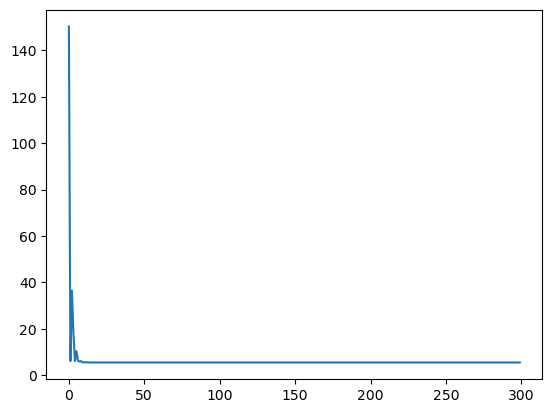

In [1]:
import torch
from torch.autograd import Variable
import torch.nn as nn
import torch.nn.functional as F

import torch.optim as optim
import matplotlib.pyplot as plt

class Net(nn.Module):
    def __init__(self):
        super(Net, self).__init__()
        self.fc1 = nn.Linear(2,1,bias=False)
    def forward(self, x):
        x = self.fc1(x)
        return x

net = Net()
print(net)


net.fc1.weight = torch.nn.Parameter(torch.tensor([[1., -1.]], requires_grad=True))

print(list(net.parameters()))

#input = torch.randn(1,2)
#out = net(input)


criterion = nn.MSELoss()
#def criterion(out, label):
#    return ((label - out)**2).mean()


optimizer = optim.SGD(net.parameters(), lr=0.01, momentum=0.5)
#optimizer = optim.Adam(net.parameters(), lr=0.005)


data = torch.tensor([[1.,3.], [2.,6.], [3.,9.]], dtype=torch.float)
target = torch.tensor([[1.],[5.],[13.]], dtype=torch.float)

hist = []

############## Batch GD based update ##############       
      
for epoch in range(300):   
    optimizer.zero_grad()
    outputs = net(data)
    loss = criterion(outputs, target)
    loss.backward()
    hist.append(loss.detach())
    optimizer.step()
    print("Epoch {} - loss: {}".format(epoch, loss))
####################################################

### Test the trained network ###
for i, current_data in enumerate(data):
    out = net(current_data)  
    print("when x = {}, y = {}".format(current_data, out))
    
plt.plot(hist, label = "training curve")

Epoch 0 - loss: 150.3333282470703
Epoch 10 - loss: 20.401926040649414
Epoch 20 - loss: 19.365339279174805
Epoch 30 - loss: 18.388254165649414
Epoch 40 - loss: 17.467729568481445
Epoch 50 - loss: 16.600908279418945
Epoch 60 - loss: 15.785148620605469
Epoch 70 - loss: 15.017838478088379
Epoch 80 - loss: 14.296577453613281
Epoch 90 - loss: 13.6190185546875
Epoch 100 - loss: 12.982964515686035
Epoch 110 - loss: 12.386283874511719
Epoch 120 - loss: 11.826985359191895
Epoch 130 - loss: 11.303153991699219
Epoch 140 - loss: 10.812970161437988
Epoch 150 - loss: 10.354676246643066
Epoch 160 - loss: 9.926650047302246
Epoch 170 - loss: 9.5272798538208
Epoch 180 - loss: 9.155094146728516
Epoch 190 - loss: 8.808659553527832
Epoch 200 - loss: 8.486612319946289
Epoch 210 - loss: 8.187661170959473
Epoch 220 - loss: 7.91057825088501
Epoch 230 - loss: 7.65419340133667
Epoch 240 - loss: 7.417400360107422
Epoch 250 - loss: 7.199121475219727
Epoch 260 - loss: 6.998363971710205
Epoch 270 - loss: 6.8141593933

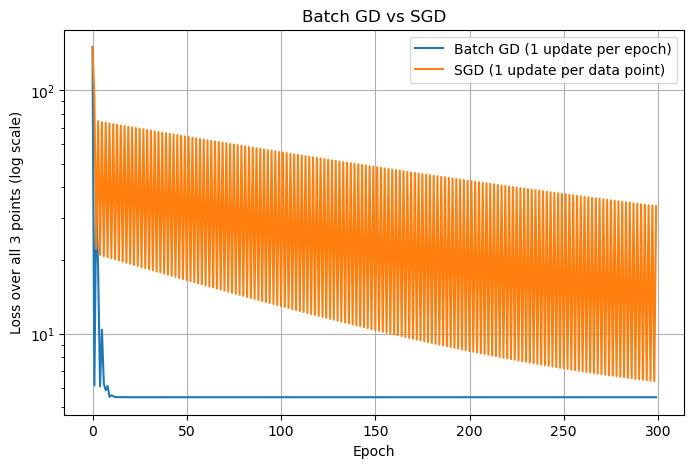

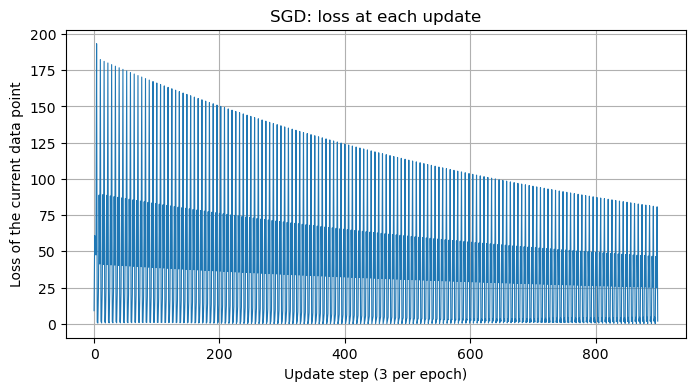

In [2]:
############## SGD based update (one update per data point) ##############
# Second model trained with SGD, so both training curves can go on one graph.
# Same starting weights and same optimizer settings as the batch model above.
net_sgd = Net()
net_sgd.fc1.weight = torch.nn.Parameter(torch.tensor([[1., -1.]], requires_grad=True))
optimizer_sgd = optim.SGD(net_sgd.parameters(), lr=0.01, momentum=0.5)

hist_sgd = []        # loss over all 3 points at the start of each epoch (same measurement as hist)
hist_sgd_step = []   # loss of the single data point used in each update

for epoch in range(300):
    with torch.no_grad():
        hist_sgd.append(criterion(net_sgd(data), target).item())
    for i in range(len(data)):
        optimizer_sgd.zero_grad()
        outputs = net_sgd(data[i])
        loss = criterion(outputs, target[i])
        loss.backward()
        hist_sgd_step.append(loss.item())
        optimizer_sgd.step()    # weight update after every data point
    if epoch % 10 == 0:
        print("Epoch {} - loss: {}".format(epoch, hist_sgd[-1]))
####################################################

### Test the trained network ###
for i, current_data in enumerate(data):
    out = net_sgd(current_data)
    print("when x = {}, y = {}".format(current_data, out))
print(list(net_sgd.parameters()))

### Compare batch GD vs SGD ###
plt.figure(figsize=(8, 5))
plt.plot([h.item() for h in hist], label="Batch GD (1 update per epoch)")
plt.plot(hist_sgd, label="SGD (1 update per data point)")
plt.yscale("log")
plt.xlabel("Epoch")
plt.ylabel("Loss over all 3 points (log scale)")
plt.title("Batch GD vs SGD")
plt.legend()
plt.grid(True)
plt.show()

### SGD loss at every single update ###
plt.figure(figsize=(8, 4))
plt.plot(hist_sgd_step, linewidth=0.8)
plt.xlabel("Update step (3 per epoch)")
plt.ylabel("Loss of the current data point")
plt.title("SGD: loss at each update")
plt.grid(True)
plt.show()
